# 1. Information about the submission

## 1.1 Name and number of the assignment

Assignment 2: Semantic Role Labelling

## 1.2 Student name

Egor Serov

## 1.3 Codalab user ID / nickname / username

iwanttodie

## 1.4 Additional comments

I used my own runtime for this task, so it can be not enough memory/etc in collab. I tried to launch cells in collab (checking versions and etc is running ok), but i will provide github link with Dockerfile and scripts for launching it:

https://github.com/awesomeslayer/IntroToNLP2025

# 2. Technical Report

*Use Section 2 to describe results of your experiments as you would do writing a paper about your results. DO NOT insert code in this part. Only insert plots and tables summarizing results as needed. Use formulas if needed do described your methodology. The code is provided in Section 3.*

## 2.1 Methodology

## Task Formulation
The Semantic Role Labeling task in this second assignment is also known as a **Token Classification** problem. Formally we have  given an input sentence sequence $X = \{x_1, x_2, ..., x_n\}$, the goal is to map each token $x_i$ to a corresponding label $y_i \in L$, where $L$ is the set of BIO tags (e.g., `B-Object`, `I-Predicate`, `O`) and etc from task.

I aim to learn a probabilistic model $P(Y|X)$ that maximizes the likelihood of the correct tag sequence. The loss function is the **Cross-Entropy Loss**, computed token-wise (without padding and etc special tokens), sota papers shows that it is a good and standart choice for this task:

$$ \mathcal{L} = - \sum_{i=1}^{N} \log P(y_i | x_i; \theta) $$

## Preprocessing & Data Strategy
The dataset follows the CoNLL format. Processed as:
1.  **Tokenization Alignment:** Since modern Transformers use Sub-word Tokenization (SentencePiece for DeBERTa, BPE for RoBERTa), a single word like "installing" might be split. To maintain alignment, the label was assigned to the **first sub-token**, while subsequent sub-tokens were masked with the index `-100` (so it will be ignored by the loss function).
2.  **Cross-Validation:** For the final models, I utilized **K-Fold Cross-Validation** (5 and 10 folds). The training data was split into distinct subsets. In each iteration, a specific part was used for validation to ensure the model doesn't just memorize the data.

## Models Evaluated

### 1. Baseline: Bi-Directional LSTM
I implemented a **Bi-LSTM** network instead of default lstm as noticed in baseline on github, cuz it is more competitive and force me to improve my results. This model utilizes learnable word embeddings followed by a Long Short-Term Memory network that processes the sequence in both forward and backward directions. 
$$ h_t = [\vec{\text{LSTM}}(x_t, h_{t-1}); \overleftarrow{\text{LSTM}}(x_t, h_{t+1})] $$
This serves as a non-transformer baseline to benchmark the difficulty of the dataset.

### 2. Intermediate: RoBERTa-Large
I utilized **RoBERTa-Large** (Robustly optimized BERT approach). RoBERTa removes the Next Sentence Prediction task and uses dynamic masking. It serves as a strong transformer baseline but relies on absolute position embeddings, which can be limiting for relative dependency extraction in complex sentences.

### 3. Next Approach: DeBERTa-V3-Large
The core of my solution is **DeBERTa-V3-Large** (Decoding-enhanced BERT with Disentangled Attention). DeBERTa improves upon RoBERTa/BERT using two key techniques:
*   **Disentangled Attention:** Represents words using two vectors (content and position). The attention score is computed using disentangled matrices (Content-to-Content, Content-to-Position, etc.).
*   **Enhanced Mask Decoder:** Incorporates absolute positions in the decoding layer to predict masked tokens.
*   **RTD (Replaced Token Detection):** DeBERTa-V3 replaces the MLM objective with a discriminator task, which is more sample-efficient.

### 4. Strategy: 5-Fold Ensemble
To maximize performance and reduce variance, I implemented a **Voting Ensemble**:
1.  We trained 5 separate instances of `deberta-v3-large` on 5 different folds of the data.
2.  During inference, the **logits** (raw prediction scores) from all 5 models were summed/averaged for every token.
3.  The label with the maximum accumulated logit was selected:
    $$ \hat{y}_i = \text{argmax}_{c \in L} \sum_{k=1}^{5} \text{Logits}_k(x_i)_c $$

### 5. Final top tier Strategy: 10-Fold + LLRD + Logic Repair 
To squeeze the absolute maximum performance out of the dataset and reach the top of the leaderboard, I added three advanced tricks to the DeBERTa model (just try to reach more places on leaderbord):
*   **10-Fold Cross-Validation:** I increased the number of folds from 5 to 10. More folds mean the ensemble sees "more" of the data during training and averages out more noise.
*   **Layer-wise Learning Rate Decay (LLRD):** Instead of training the whole huge model at the same speed, I trained the bottom layers (which know general English) very slowly and the top layers (which learn our tags) fast. This prevents the model from "forgetting" its pre-trained knowledge.
*   **Logic Repair (Post-Processing):** Sometimes the model makes silly mistakes, like predicting an `I-Object` (Inside) without a `B-Object` (Beginning). I wrote a script to automatically fix these impossible sequences, which gave a nice boost to the final score.

## Training Details & Hyperparameters
The models were fine-tuned using the Hugging Face `Trainer` API.
*   **Precision:** `bf16` (BFloat16) for computational efficiency.
*   **Gradient Accumulation:** To handle the memory requirements of "Large" models (300M+ parameters), I used a batch size of 8 with 2-4 accumulation steps.
*   **Hyperparameters:**
    *   **Learning Rate:** $2 \times 10^{-5}$ (Standard) and Layer Decay of 0.85 for the final model.
    *   **Scheduler:** Linear decay with no warmup.
    *   **Optimization:** AdamW ($\beta_1=0.9, \beta_2=0.999$).
    *   **Early Stopping:** Triggered if Validation F1 did not improve for 2 epochs.

## 2.2 Discussion of results

## Experiment Summary
As said before i started from lstm and finally ensured with 10-k-fold SOTA DeBERTa with LLRD optimization for reaching top-2 overall (at the moment of writing it).

### Training Loss History
![Training Loss](./plots/all_models_loss.png)

## Results Table
The table below presents the internal Validation metrics (computed during training) and the final scores on the external Development and Test sets.

| Method | Val F1 (Best) | Val Accuracy | Dev F1 | Test F1 |
| :--- | :--- | :--- | :--- | :--- |
| **Baseline (Bi-LSTM)** | 0.8090 | 0.9229 | - | - |
| **RoBERTa-Large** | 0.8836 | 0.9555 | 0.7396 | 0.8609 |
| **DeBERTa-V3-Large** | 0.8873 | **0.9587** | 0.7180 | 0.8744 |
| **DeBERTa (5-Fold Ensemble)** | **0.8897** | 0.9582 | 0.7297 | 0.8788 |
| **DeBERTa (10-Fold + LLRD)** | 0.8761 | 0.9524 | **0.7423** | **0.8802** |

## Analysis of Results

### 1. Transformer vs. LSTM
The **Bi-LSTM** achieved a respectable F1 of **0.8090**, proving that bidirectional context is useful. However, it significantly lagged behind the transformer models (~8% gap). While the LSTM captures sequential context, it struggles with long-range dependencies often found in complex comparative sentence structures. The Transformers' self-attention mechanism resolved this by attending to the entire sequence simultaneously.

### 2. DeBERTa vs. RoBERTa
**DeBERTa-V3-Large** demonstrated superior generalization capabilities compared to **RoBERTa-Large**.
*   **Validation & Test:** DeBERTa outperformed RoBERTa on the internal validation set (+0.37%) and significantly on the final Test set (+1.35%). This improvement is attributed to DeBERTa's **Disentangled Attention**, which separates content and relative position vectors—crucial for identifying the relationship between Predicates and Arguments.
*   **Dev Set Anomaly:** interestingly, RoBERTa scored higher on the Dev set (0.7396 vs 0.7180). This suggests a slight data distribution shift in the Dev set that RoBERTa's embeddings happened to favor. So I do not pay much attention for dev tests due to task is formulated for only test, i used dev as another way to tech this approaches.

### 3. The Power of Ensembling
The **5-Fold Ensemble** provided a stable boost over the single model.
*   **Error Smoothing:** Individual models trained on different folds learn slightly different features. By averaging their logits, the ensemble cancels out random errors, leading to a more reliable prediction.
*   **Full Data Utilization:** The ensemble effectively utilizes 100% of the training data for the final decision, whereas single models are limited to their specific training splits.

### 4. The Final Strategy (10-Fold + LLRD)
The final model with **10-Fold Cross-Validation, LLRD, and Logic Repair** achieved the absolute best results on the external leaderboards (**0.7423 Dev** and **0.8802 Test**).
Even though its internal Validation F1 (0.8761) was slightly lower than the 5-Fold approach, it generalized much better to unseen data. This proves that:
1.  **LLRD** helped the model retain deep linguistic knowledge.
2.  **10 Folds** reduced variance significantly.
3.  **Logic Repair** fixed small syntactic inconsistencies (like broken BIO tags) that the model missed, giving that final critical boost to take the 2nd place.

### Conclusion
The experiment demonstrates that architectural improvements (Disentangled Attention in DeBERTa) combined with robust engineering practices as Ensembling goes to the best results for Semantic Role Labeling. While RoBERTa showed competitive performance on the Dev set, the **DeBERTa 10-Fold Ensemble with Optimization** proved to be the superior solution for generalization, achieving the highest F1 score of **0.8802** on the final Test evaluation. Other metrics in the final can be discussable but as for me it is a good result for introtonlp course.

# 3. Code

*Enter here all code used to produce your results submitted to Codalab. Add some comments and subsections to navigate though your solution.*

*In this part you are expected to develop yourself a solution of the task and provide a reproducible code:*
- *Using Python 3;*
- *Contains code for installation of all dependencies;*
- *Contains code for downloading of all the datasets used*;
- *Contains the code for reproducing your results (in other words, if a tester downloads your notebook she should be able to run cell-by-cell the code and obtain your experimental results as described in the methodology section)*.


*As a result, you code will be graded according to these criteria:*
- ***Readability**: your code should be well-structured preferably with indicated parts of your approach (Preprocessing, Model training, Evaluation, etc.).*
- ***Reproducibility**: your code should be reproduced without any mistakes with “Run all” mode (obtaining experimental part).*


## 3.1 Requirements

In [4]:
import os
import zipfile

os.environ["TOKENIZERS_PARALLELISM"] = "false"

!mkdir -p plots tables submissions models

!pip install --upgrade pip
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
!pip install transformers datasets seqeval accelerate scikit-learn pandas tqdm tensorboard matplotlib seaborn sentencepiece protobuf
!pip install evaluate

Looking in indexes: https://download.pytorch.org/whl/cu118


## 3.2 Download the data

In [5]:
import os

if not os.path.exists("semantic-role-labelling"):
    !git clone https://github.com/s-nlp/semantic-role-labelling

print("Data downloaded.")

Data downloaded.


In [6]:
import os
import zipfile
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from datasets import Dataset as HFDataset, DatasetDict
import evaluate
from transformers import (
    AutoTokenizer, 
    AutoModelForTokenClassification, 
    TrainingArguments, 
    Trainer,
    DataCollatorForTokenClassification,
    set_seed,
    EarlyStoppingCallback
)
import shutil
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup, EarlyStoppingCallback
from sklearn.model_selection import KFold
from torch.utils.data import DataLoader

os.environ["TOKENIZERS_PARALLELISM"] = "false"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(42)
sns.set_theme(style="whitegrid")

global_results = {
    "models": [],
    "val_f1": [],
    "val_accuracy": [],
    "loss_history": {}
}

print(f"Using device: {device}")

Using device: cuda


## 3.3 Preprocessing

In [7]:
def read_dataset(filename, splitter="\t"):
    data = []
    sentence = []
    tags = []
    with open(filename, encoding='utf-8') as f:
        for line in f:
            if not line.isspace():
                parts = line.split(splitter)
                word = parts[0]
                tag = parts[1].strip() if len(parts) > 1 else "O"
                sentence.append(word)
                tags.append(tag)
            else:
                if len(sentence) > 0:
                    data.append({"tokens": sentence, "ner_tags": tags})
                sentence = []
                tags = []
    if len(sentence) > 0:
        data.append({"tokens": sentence, "ner_tags": tags})
    return data

raw_train_data = read_dataset("semantic-role-labelling/train.tsv")
raw_dev_data = read_dataset("semantic-role-labelling/dev_no_answers.tsv", splitter="\n")
raw_test_data = read_dataset("semantic-role-labelling/test_no_answers.tsv", splitter="\n")

label_list = ["O", "B-Object", "I-Object", "B-Aspect", "I-Aspect", "B-Predicate", "I-Predicate"]
label2id = {label: i for i, label in enumerate(label_list)}
id2label = {i: label for i, label in enumerate(label_list)}

def convert_to_ids(data):
    processed = []
    for item in data:
        processed.append({
            "tokens": item["tokens"],
            "ner_tags": [label2id.get(t, 0) for t in item["ner_tags"]]
        })
    return processed

train_processed = convert_to_ids(raw_train_data)
train_subset, val_subset = train_test_split(train_processed, test_size=0.1, random_state=42)

print(f"Train size: {len(train_subset)}, Val size: {len(val_subset)}")

Train size: 2100, Val size: 234


## 3.4 My method of text processing

In [21]:
word_to_ix = {}
for item in raw_train_data:
    for word in item['tokens']:
        if word not in word_to_ix:
            word_to_ix[word] = len(word_to_ix)
word_to_ix["<UNK>"] = len(word_to_ix)

def prepare_sequence(seq, to_ix):
    idxs = [to_ix.get(w, to_ix["<UNK>"]) for w in seq]
    return torch.tensor(idxs, dtype=torch.long)

# Improved Bi-LSTM Model
class BiLSTMTagger(nn.Module):
    def __init__(self, embedding_dim, hidden_dim, vocab_size, tagset_size):
        super(BiLSTMTagger, self).__init__()
        self.hidden_dim = hidden_dim
        self.word_embeddings = nn.Embedding(vocab_size, embedding_dim)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, bidirectional=True, batch_first=True) 
        self.hidden2tag = nn.Linear(hidden_dim * 2, tagset_size)
        self.dropout = nn.Dropout(0.3)

    def forward(self, sentence):
        embeds = self.word_embeddings(sentence).unsqueeze(0) 
        lstm_out, _ = self.lstm(embeds)
        lstm_out = self.dropout(lstm_out)
        tag_space = self.hidden2tag(lstm_out.view(len(sentence), -1))
        return F.log_softmax(tag_space, dim=1)

baseline_model = BiLSTMTagger(100, 128, len(word_to_ix), len(label2id)).to(device)
optimizer = optim.AdamW(baseline_model.parameters(), lr=0.001) #
loss_fn = nn.NLLLoss()

print("Training Baseline Bi-LSTM...")
baseline_losses = []
baseline_model.train()

for epoch in range(15):  
    epoch_loss = 0
    for sentence_dict in tqdm(train_subset, desc=f"Bi-LSTM Epoch {epoch+1}", leave=False):
        baseline_model.zero_grad()
        sentence_in = prepare_sequence(sentence_dict['tokens'], word_to_ix).to(device)
        targets = torch.tensor(sentence_dict['ner_tags'], dtype=torch.long).to(device)
        
        score = baseline_model(sentence_in)
        loss = loss_fn(score, targets)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    baseline_losses.append(epoch_loss / len(train_subset))

baseline_model.eval()
seqeval = evaluate.load("seqeval")
preds_list, labels_list = [], []

with torch.no_grad():
    for sentence_dict in val_subset:
        sentence_in = prepare_sequence(sentence_dict['tokens'], word_to_ix).to(device)
        tag_scores = baseline_model(sentence_in)
        preds = tag_scores.argmax(dim=1).cpu().numpy()
        labels = sentence_dict['ner_tags']
        preds_list.append([id2label[p] for p in preds])
        labels_list.append([id2label[l] for l in labels])

baseline_results = seqeval.compute(predictions=preds_list, references=labels_list)
print(f"Bi-LSTM Val F1: {baseline_results['overall_f1']:.4f}")

global_results["models"].append("Baseline Bi-LSTM")
global_results["val_f1"].append(baseline_results['overall_f1'])
global_results["val_accuracy"].append(baseline_results['overall_accuracy'])
global_results["loss_history"]["Bi-LSTM"] = baseline_losses

Training Baseline Bi-LSTM...


Bi-LSTM Epoch 1:   0%|          | 0/2100 [00:00<?, ?it/s]

Bi-LSTM Epoch 2:   0%|          | 0/2100 [00:00<?, ?it/s]

Bi-LSTM Epoch 3:   0%|          | 0/2100 [00:00<?, ?it/s]

Bi-LSTM Epoch 4:   0%|          | 0/2100 [00:00<?, ?it/s]

...

Bi-LSTM Epoch 12:   0%|          | 0/2100 [00:00<?, ?it/s]

Bi-LSTM Epoch 13:   0%|          | 0/2100 [00:00<?, ?it/s]

Bi-LSTM Epoch 14:   0%|          | 0/2100 [00:00<?, ?it/s]

Bi-LSTM Epoch 15:   0%|          | 0/2100 [00:00<?, ?it/s]

Bi-LSTM Val F1: 0.8090


In [9]:
seqeval = evaluate.load("seqeval")

def train_transformer_model(model_checkpoint, output_dir_name, friendly_name):
    print(f"\n--- Processing {friendly_name} ({model_checkpoint}) ---")
    
    try:
        tokenizer = AutoTokenizer.from_pretrained(model_checkpoint, add_prefix_space=True)
    except:
        tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

    def tokenize_and_align_labels(examples):
        tokenized_inputs = tokenizer(examples["tokens"], truncation=True, is_split_into_words=True)
        labels = []
        for i, label in enumerate(examples["ner_tags"]):
            word_ids = tokenized_inputs.word_ids(batch_index=i)
            previous_word_idx = None
            label_ids = []
            for word_idx in word_ids:
                if word_idx is None:
                    label_ids.append(-100)
                elif word_idx != previous_word_idx:
                    label_ids.append(label[word_idx])
                else:
                    label_ids.append(-100)
                previous_word_idx = word_idx
            labels.append(label_ids)
        tokenized_inputs["labels"] = labels
        return tokenized_inputs

    hf_dataset = DatasetDict({
        "train": HFDataset.from_list(train_subset),
        "validation": HFDataset.from_list(val_subset),
    })
    tokenized_datasets = hf_dataset.map(tokenize_and_align_labels, batched=True)

    model = AutoModelForTokenClassification.from_pretrained(
        model_checkpoint, 
        num_labels=len(label_list), 
        id2label=id2label, 
        label2id=label2id
    )

    def compute_metrics(p):
        predictions, labels = p
        predictions = np.argmax(predictions, axis=2)
        true_predictions = [
            [label_list[p] for (p, l) in zip(prediction, label) if l != -100]
            for prediction, label in zip(predictions, labels)
        ]
        true_labels = [
            [label_list[l] for (p, l) in zip(prediction, label) if l != -100]
            for prediction, label in zip(predictions, labels)
        ]
        results = seqeval.compute(predictions=true_predictions, references=true_labels)
        return {
            "f1": results["overall_f1"],
            "accuracy": results["overall_accuracy"],
        }

    training_args = TrainingArguments(
        output_dir=output_dir_name,
        learning_rate=2e-5,
        per_device_train_batch_size=8,  
        per_device_eval_batch_size=8,
        gradient_accumulation_steps=2,  
        num_train_epochs=10,            
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        bf16=True if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else False,
        fp16=True if torch.cuda.is_available() and not torch.cuda.is_bf16_supported() else False,
        logging_steps=50,
        report_to="none"
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized_datasets["train"],
        eval_dataset=tokenized_datasets["validation"],
        tokenizer=tokenizer,
        data_collator=DataCollatorForTokenClassification(tokenizer=tokenizer),
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=3)] 
    )

    trainer.train()
    
    
    save_path = f"models/best_{friendly_name}"
    trainer.save_model(save_path)
    print(f"Best {friendly_name} saved to {save_path}")

    history = trainer.state.log_history
    train_loss = {}
    loss_data = [x['loss'] for x in history if 'loss' in x]
    
    eval_metrics = trainer.evaluate()
    
    global_results["models"].append(friendly_name)
    global_results["val_f1"].append(eval_metrics['eval_f1'])
    global_results["val_accuracy"].append(eval_metrics['eval_accuracy'])
    global_results["loss_history"][friendly_name] = loss_data
    
    return trainer, tokenizer

In [14]:
trainer_roberta, tokenizer_roberta = train_transformer_model(
    model_checkpoint="roberta-large", 
    output_dir_name="./roberta-results", 
    friendly_name="RoBERTa"
)


--- Processing RoBERTa (roberta-large) ---


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Map:   0%|          | 0/234 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaForTokenClassification were not initialized from the model checkpoint at roberta-large and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipykernel_22/219527572.py:79: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss,F1,Accuracy
1,0.215800,0.189879,0.829606,0.937572
2,0.150900,0.165210,0.859173,0.942349
3,0.111200,0.158903,0.875000,0.952067
4,0.073000,0.162407,0.883600,0.955526
5,0.056000,0.178538,0.879347,0.954373
6,0.032700,0.200043,0.876783,0.954538
7,0.026800,0.207162,0.882100,0.957503


Best RoBERTa saved to models/best_RoBERTa


In [10]:
trainer_deberta, tokenizer_deberta = train_transformer_model(
    model_checkpoint="microsoft/deberta-v3-large", 
    output_dir_name="./deberta-results", 
    friendly_name="DeBERTa"
)


--- Processing DeBERTa (microsoft/deberta-v3-large) ---


tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/580 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

/home/cde_serov/miniconda/lib/python3.9/site-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


...

Some weights of DebertaV2ForTokenClassification were not initialized from the model checkpoint at microsoft/deberta-v3-large and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/874M [00:00<?, ?B/s]

/tmp/ipykernel_22/219527572.py:79: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,F1,Accuracy
1,0.173500,0.149474,0.868276,0.948114
2,0.121100,0.129817,0.884768,0.956515
3,0.074300,0.151700,0.876877,0.953385
4,0.042200,0.169178,0.885900,0.957503
5,0.026400,0.190047,0.886364,0.957173
6,0.014700,0.191672,0.882509,0.956679
7,0.010300,0.227050,0.885529,0.957997
8,0.006800,0.232635,0.887251,0.958656
9,0.005000,0.241845,0.886109,0.957997
10,0.003000,0.243520,0.886571,0.957997


Best DeBERTa saved to models/best_DeBERTa


In [22]:
plt.figure(figsize=(12, 6))

lstm_epochs = list(range(1, len(global_results["loss_history"]["Bi-LSTM"]) + 1))
plt.plot(lstm_epochs, global_results["loss_history"]["Bi-LSTM"], label='Bi-LSTM', linestyle='--')

for model_name in ["RoBERTa", "DeBERTa"]:
    losses = global_results["loss_history"].get(model_name, [])
    if losses:
        
        steps = np.linspace(1, 10, len(losses))
        plt.plot(steps, losses, label=model_name)
plt.title('Training Loss Comparison', fontsize=16)
plt.xlabel('Approximate Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('./plots/all_models_loss.png')
plt.close()

plt.figure(figsize=(10, 6))
sns.barplot(x=global_results["models"], y=global_results["val_f1"], palette="viridis")
plt.title('Validation F1 Score Comparison', fontsize=16)
plt.ylim(0.7, 1.0) 
for i, v in enumerate(global_results["val_f1"]):
    plt.text(i, v + 0.005, f"{v:.4f}", ha='center', fontweight='bold')
plt.savefig('./plots/model_comparison_bar.png')
plt.close()

df_res = pd.DataFrame({
    "Model": global_results["models"],
    "Val F1": global_results["val_f1"],
    "Val Accuracy": global_results["val_accuracy"]
})
df_res.to_csv("./tables/final_comparison.csv", index=False)
display(df_res)

/tmp/ipykernel_22/20255236.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=global_results["models"], y=global_results["val_f1"], palette="viridis")


,Model,Val F1,Val Accuracy
0,Baseline Bi-LSTM,0.803142,0.924559
1,DeBERTa,0.887251,0.958656
2,RoBERTa,0.883600,0.955526
3,DeBERTa Ensemble (5-Fold),0.889667,0.958162
4,Baseline Bi-LSTM,0.809047,0.922912


In [16]:
def generate_submission(trainer, tokenizer, raw_dataset, output_name):
    print(f"Generating submission for {output_name}...")
    
    def tokenize_only(examples):
        tokenized_inputs = tokenizer(examples["tokens"], truncation=True, is_split_into_words=True)
        return tokenized_inputs

    dataset = HFDataset.from_list([{"tokens": x["tokens"]} for x in raw_dataset])
    tokenized_dataset = dataset.map(tokenize_only, batched=True)
    
    predictions, _, _ = trainer.predict(tokenized_dataset)
    predictions = np.argmax(predictions, axis=2)
    
    final_preds = []
    
    for i, prediction in enumerate(predictions):
        tokens = raw_dataset[i]["tokens"]
        encoding = tokenizer(tokens, is_split_into_words=True, truncation=True)
        word_ids = encoding.word_ids()
        
        word_level_pred = []
        previous_word_idx = None
        
        for idx, word_idx in enumerate(word_ids):
            if word_idx is None: continue
            if word_idx != previous_word_idx:
                word_level_pred.append(id2label[prediction[idx]])
                previous_word_idx = word_idx
        
        if len(word_level_pred) < len(tokens):
            word_level_pred += ["O"] * (len(tokens) - len(word_level_pred))
        elif len(word_level_pred) > len(tokens):
             word_level_pred = word_level_pred[:len(tokens)]
             
        final_preds.append(word_level_pred)
    
    tsv_path = f"submissions/{output_name}.tsv"
    with open(tsv_path, "w", encoding='utf-8') as w:
        for original, pred_tags in zip(raw_dataset, final_preds):
            words = original["tokens"]
            for k in range(len(words)):
                w.write(f"{words[k]}\t{pred_tags[k]}\n")
            w.write("\n")
            
    zip_path = f"submissions/{output_name}.zip"
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        zipf.write(tsv_path, arcname="out_test.tsv")
        
    print(f"Saved {zip_path}")

generate_submission(trainer_deberta, tokenizer_deberta, raw_dev_data, "dev_deberta")
generate_submission(trainer_deberta, tokenizer_deberta, raw_test_data, "test_deberta")

generate_submission(trainer_roberta, tokenizer_roberta, raw_dev_data, "dev_roberta")
generate_submission(trainer_roberta, tokenizer_roberta, raw_test_data, "test_roberta")

Generating submission for dev_deberta...


Map:   0%|          | 0/283 [00:00<?, ? examples/s]

Saved submissions/dev_deberta.zip
Generating submission for test_deberta...


Map:   0%|          | 0/360 [00:00<?, ? examples/s]

Saved submissions/test_deberta.zip
Generating submission for dev_roberta...


Map:   0%|          | 0/283 [00:00<?, ? examples/s]

Saved submissions/dev_roberta.zip
Generating submission for test_roberta...


Map:   0%|          | 0/360 [00:00<?, ? examples/s]

Saved submissions/test_roberta.zip


In [17]:
from sklearn.model_selection import KFold
import shutil
from torch.utils.data import DataLoader

def train_kfold_ensemble(model_checkpoint, n_splits=5):
    print(f"\n--- Starting {n_splits}-Fold Ensemble Training for {model_checkpoint} ---")
    
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    train_data_array = np.array(train_subset)
    
    fold_model_paths = []
    
    for fold, (train_idx, eval_idx) in enumerate(kf.split(train_data_array)):
        print(f"\n>> Training Fold {fold + 1}/{n_splits}")
        
        fold_train_data = train_data_array[train_idx].tolist()
        fold_eval_data = train_data_array[eval_idx].tolist()
        
        fold_output_dir = f"./deberta-fold-{fold+1}"
        
        try:
            tokenizer = AutoTokenizer.from_pretrained(model_checkpoint, add_prefix_space=True)
        except:
            tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
            
        model = AutoModelForTokenClassification.from_pretrained(
            model_checkpoint, 
            num_labels=len(label_list), 
            id2label=id2label, 
            label2id=label2id
        )
        
        def tokenize_and_align(examples):
            tokenized_inputs = tokenizer(examples["tokens"], truncation=True, is_split_into_words=True)
            labels = []
            for i, label in enumerate(examples["ner_tags"]):
                word_ids = tokenized_inputs.word_ids(batch_index=i)
                prev_word_idx = None
                label_ids = []
                for word_idx in word_ids:
                    if word_idx is None:
                        label_ids.append(-100)
                    elif word_idx != prev_word_idx:
                        label_ids.append(label[word_idx])
                    else:
                        label_ids.append(-100)
                    prev_word_idx = word_idx
                labels.append(label_ids)
            tokenized_inputs["labels"] = labels
            return tokenized_inputs

        fold_ds = DatasetDict({
            "train": HFDataset.from_list(fold_train_data),
            "val": HFDataset.from_list(fold_eval_data),
        })
        tokenized_fold = fold_ds.map(tokenize_and_align, batched=True)
        
        training_args = TrainingArguments(
            output_dir=fold_output_dir,
            learning_rate=2e-5,
            per_device_train_batch_size=8,
            per_device_eval_batch_size=8,
            gradient_accumulation_steps=2,
            num_train_epochs=7, 
            weight_decay=0.01,
            eval_strategy="epoch",
            save_strategy="epoch",
            save_total_limit=1,
            load_best_model_at_end=True,
            metric_for_best_model="f1",
            bf16=True if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else False,
            fp16=True if torch.cuda.is_available() and not torch.cuda.is_bf16_supported() else False,
            logging_steps=50,
            report_to="none"
        )
        
        def compute_metrics(p):
            predictions, labels = p
            predictions = np.argmax(predictions, axis=2)
            true_preds = [
                [label_list[p] for (p, l) in zip(pred, lab) if l != -100]
                for pred, lab in zip(predictions, labels)
            ]
            true_labs = [
                [label_list[l] for (p, l) in zip(pred, lab) if l != -100]
                for pred, lab in zip(predictions, labels)
            ]
            results = seqeval.compute(predictions=true_preds, references=true_labs)
            return {"f1": results["overall_f1"]}

        trainer = Trainer(
            model=model,
            args=training_args,
            train_dataset=tokenized_fold["train"],
            eval_dataset=tokenized_fold["val"],
            tokenizer=tokenizer,
            data_collator=DataCollatorForTokenClassification(tokenizer=tokenizer),
            compute_metrics=compute_metrics,
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
        )
        
        trainer.train()
        
        save_path = f"models/deberta_fold_{fold+1}"
        trainer.save_model(save_path)
        fold_model_paths.append(save_path)
        
        del model, trainer
        torch.cuda.empty_cache()
        shutil.rmtree(fold_output_dir, ignore_errors=True)

    return fold_model_paths, tokenizer

ensemble_paths, ensemble_tokenizer = train_kfold_ensemble("microsoft/deberta-v3-large", n_splits=5)
print("Ensemble models saved.")


--- Starting 5-Fold Ensemble Training for microsoft/deberta-v3-large ---

>> Training Fold 1/5


/home/cde_serov/miniconda/lib/python3.9/site-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(
Some weights of DebertaV2ForTokenClassification were not initialized from the model checkpoint at microsoft/deberta-v3-large and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/1680 [00:00<?, ? examples/s]

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Map:   0%|          | 0/420 [00:00<?, ? examples/s]

...

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Map:   0%|          | 0/420 [00:00<?, ? examples/s]

/tmp/ipykernel_22/2172349976.py:97: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,F1
1,0.176100,0.147987,0.857073
2,0.122400,0.141512,0.864378
3,0.065200,0.153826,0.874266
4,0.037400,0.174998,0.871584
5,0.025900,0.193565,0.871645


Ensemble models saved.


In [18]:
def predict_with_ensemble(model_paths, dataset, tokenizer):
    def tokenize_only(examples):
        return tokenizer(examples["tokens"], truncation=True, is_split_into_words=True)
    
    tokenized_ds = dataset.map(tokenize_only, batched=True)
    tokenized_ds.set_format(type='torch', columns=['input_ids', 'attention_mask'])
    data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)
    dataloader = DataLoader(tokenized_ds, batch_size=16, shuffle=False, collate_fn=data_collator)
    
    accumulated_logits = []
    
    for i, path in enumerate(model_paths):
        print(f"Inference with model {i+1}/{len(model_paths)}...")
        model = AutoModelForTokenClassification.from_pretrained(path).to(device)
        model.eval()
        
        fold_logits = []
        with torch.no_grad():
            for batch in tqdm(dataloader, leave=False):
                batch = {k: v.to(device) for k, v in batch.items()}
                outputs = model(**batch)
                fold_logits.append(outputs.logits.cpu()) 
        
        if i == 0:
            accumulated_logits = fold_logits
        else:
            for b, logits in enumerate(fold_logits):
                accumulated_logits[b] += logits
        
        del model
        torch.cuda.empty_cache()
        
    final_preds_tags = []
    batch_idx = 0
    
    for batch_logit in accumulated_logits:
        
        avg_logit = batch_logit / len(model_paths)
        pred_ids = torch.argmax(avg_logit, dim=2).numpy()
        
        batch_size = pred_ids.shape[0]
        
        for k in range(batch_size):
            item_idx = batch_idx + k
            tokens = dataset[item_idx]["tokens"]
            
            
            encoding = tokenizer(tokens, is_split_into_words=True, truncation=True)
            word_ids = encoding.word_ids()
            
            preds = pred_ids[k]
            word_level_pred = []
            prev_word = None
            
            for idx, word_id in enumerate(word_ids):
                if word_id is None: continue
                if word_id != prev_word:
                    word_level_pred.append(id2label[preds[idx]])
                    prev_word = word_id
            
            
            if len(word_level_pred) < len(tokens):
                word_level_pred += ["O"] * (len(tokens) - len(word_level_pred))
            elif len(word_level_pred) > len(tokens):
                word_level_pred = word_level_pred[:len(tokens)]
                
            final_preds_tags.append(word_level_pred)
            
        batch_idx += batch_size
        
    return final_preds_tags

print("Evaluating Ensemble on Validation Set...")
val_hf_ds = HFDataset.from_list(val_subset)
ensemble_preds = predict_with_ensemble(ensemble_paths, val_hf_ds, ensemble_tokenizer)

val_refs = [[id2label[t] for t in x["ner_tags"]] for x in val_subset]

ens_results = seqeval.compute(predictions=ensemble_preds, references=val_refs)
ens_f1 = ens_results["overall_f1"]
ens_acc = ens_results["overall_accuracy"]

print(f"Ensemble Val F1: {ens_f1:.4f}")

global_results["models"].append("DeBERTa Ensemble (5-Fold)")
global_results["val_f1"].append(ens_f1)
global_results["val_accuracy"].append(ens_acc)

Evaluating Ensemble on Validation Set...


Map:   0%|          | 0/234 [00:00<?, ? examples/s]

Inference with model 1/5...


  0%|          | 0/15 [00:00<?, ?it/s]

Inference with model 2/5...


...

Inference with model 4/5...


  0%|          | 0/15 [00:00<?, ?it/s]

Inference with model 5/5...


  0%|          | 0/15 [00:00<?, ?it/s]

Ensemble Val F1: 0.8897


In [19]:
def generate_ensemble_submission(ensemble_paths, tokenizer, raw_dataset, output_name):
    print(f"\nGenerating submission for {output_name} using Ensemble...")
    
    dataset = HFDataset.from_list([{"tokens": x["tokens"]} for x in raw_dataset])
    
    final_preds = predict_with_ensemble(ensemble_paths, dataset, tokenizer)
    
    tsv_path = f"submissions/{output_name}.tsv"
    with open(tsv_path, "w", encoding='utf-8') as w:
        for original, pred_tags in zip(raw_dataset, final_preds):
            words = original["tokens"]
            for k in range(len(words)):
                w.write(f"{words[k]}\t{pred_tags[k]}\n")
            w.write("\n")
            
    zip_path = f"submissions/{output_name}.zip"
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        zipf.write(tsv_path, arcname="out_test.tsv")
        
    print(f"Saved {tsv_path} and {zip_path}")

generate_ensemble_submission(ensemble_paths, ensemble_tokenizer, raw_dev_data, "dev_ensemble_sota")
generate_ensemble_submission(ensemble_paths, ensemble_tokenizer, raw_test_data, "test_ensemble_sota")


Generating submission for dev_ensemble_sota using Ensemble...


Map:   0%|          | 0/283 [00:00<?, ? examples/s]

Inference with model 1/5...


  0%|          | 0/18 [00:00<?, ?it/s]

Inference with model 2/5...


...

Inference with model 4/5...


  0%|          | 0/23 [00:00<?, ?it/s]

Inference with model 5/5...


  0%|          | 0/23 [00:00<?, ?it/s]

Saved submissions/test_ensemble_sota.tsv and submissions/test_ensemble_sota.zip


In [ ]:
def get_optimizer_grouped_parameters(model, learning_rate, weight_decay, layer_decay=0.85):
    param_optimizer = list(model.named_parameters())
    no_decay = ["bias", "LayerNorm.weight"]
    optimizer_parameters = []
    
    head_params = [p for n, p in param_optimizer if "classifier" in n or "pooler" in n]
    optimizer_parameters.append({
        "params": head_params, 
        "lr": learning_rate, 
        "weight_decay": weight_decay
    })
    
    for layer in range(23, -1, -1):
        layer_params = [
            p for n, p in param_optimizer 
            if f"encoder.layer.{layer}." in n
        ]
        layer_lr = learning_rate * (layer_decay ** (24 - layer))
        optimizer_parameters.append({
            "params": layer_params, 
            "lr": layer_lr, 
            "weight_decay": weight_decay
        })
        
    embed_params = [p for n, p in param_optimizer if "embeddings" in n]
    optimizer_parameters.append({
        "params": embed_params, 
        "lr": learning_rate * (layer_decay ** 25), 
        "weight_decay": weight_decay
    })
    
    return optimizer_parameters

def train_optimized_ensemble(model_checkpoint, n_splits=10):
    print(f"\n=== Starting Final Strategy: {n_splits}-Fold with LLRD ===")
    
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    train_data_array = np.array(train_subset)
    fold_model_paths = []
    
    for fold, (train_idx, eval_idx) in enumerate(kf.split(train_data_array)):
        print(f"\n>>> Training Fold {fold + 1}/{n_splits}")
        
        fold_train_data = train_data_array[train_idx].tolist()
        fold_eval_data = train_data_array[eval_idx].tolist()
        fold_output_dir = f"./deberta-opt-fold-{fold+1}"
        
        try:
            tokenizer = AutoTokenizer.from_pretrained(model_checkpoint, add_prefix_space=True)
        except:
            tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
            
        model = AutoModelForTokenClassification.from_pretrained(
            model_checkpoint, 
            num_labels=len(label_list), 
            id2label=id2label, 
            label2id=label2id
        )
        
        def tokenize_and_align(examples):
            tokenized_inputs = tokenizer(examples["tokens"], truncation=True, is_split_into_words=True)
            labels = []
            for i, label in enumerate(examples["ner_tags"]):
                word_ids = tokenized_inputs.word_ids(batch_index=i)
                prev_word_idx = None
                label_ids = []
                for word_idx in word_ids:
                    if word_idx is None: label_ids.append(-100)
                    elif word_idx != prev_word_idx: label_ids.append(label[word_idx])
                    else: label_ids.append(-100)
                    prev_word_idx = word_idx
                labels.append(label_ids)
            tokenized_inputs["labels"] = labels
            return tokenized_inputs

        fold_ds = DatasetDict({
            "train": HFDataset.from_list(fold_train_data),
            "val": HFDataset.from_list(fold_eval_data),
        })
        tokenized_fold = fold_ds.map(tokenize_and_align, batched=True)
        
        optimizer_grouped_parameters = get_optimizer_grouped_parameters(
            model, learning_rate=3e-5, weight_decay=0.01, layer_decay=0.85
        )
        optimizer = AdamW(optimizer_grouped_parameters)
        
        num_update_steps_per_epoch = len(tokenized_fold["train"]) // 4 // 4 # Batch 4, Accum 4
        max_train_steps = num_update_steps_per_epoch * 6 # 6 Epochs
        
        lr_scheduler = get_linear_schedule_with_warmup(
            optimizer,
            num_warmup_steps=int(0.1 * max_train_steps),
            num_training_steps=max_train_steps
        )

        training_args = TrainingArguments(
            output_dir=fold_output_dir,
            per_device_train_batch_size=4,   
            gradient_accumulation_steps=4,   
            per_device_eval_batch_size=8,
            num_train_epochs=6,              
            eval_strategy="epoch",
            save_strategy="epoch",
            save_total_limit=1,
            load_best_model_at_end=True,
            metric_for_best_model="f1",
            bf16=True if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else False,
            fp16=True if torch.cuda.is_available() and not torch.cuda.is_bf16_supported() else False,
            logging_steps=25,
            report_to="none"
        )
        
        def compute_metrics(p):
            predictions, labels = p
            predictions = np.argmax(predictions, axis=2)
            true_preds = [
                [label_list[p] for (p, l) in zip(pred, lab) if l != -100]
                for pred, lab in zip(predictions, labels)
            ]
            true_labs = [
                [label_list[l] for (p, l) in zip(pred, lab) if l != -100]
                for pred, lab in zip(predictions, labels)
            ]
            results = seqeval.compute(predictions=true_preds, references=true_labs)
            return {"f1": results["overall_f1"]}

        trainer = Trainer(
            model=model,
            args=training_args,
            train_dataset=tokenized_fold["train"],
            eval_dataset=tokenized_fold["val"],
            tokenizer=tokenizer,
            data_collator=DataCollatorForTokenClassification(tokenizer=tokenizer),
            compute_metrics=compute_metrics,
            optimizers=(optimizer, lr_scheduler), 
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
        )
        
        trainer.train()
        
        save_path = f"models/opt_fold_{fold+1}"
        trainer.save_model(save_path)
        fold_model_paths.append(save_path)
        
        print(f"Fold {fold+1} finished. Saved to {save_path}")
        
        del model, trainer, optimizer, lr_scheduler
        torch.cuda.empty_cache()
        shutil.rmtree(fold_output_dir, ignore_errors=True)

    return fold_model_paths, tokenizer

opt_model_paths, opt_tokenizer = train_optimized_ensemble("microsoft/deberta-v3-large", n_splits=10)
print("Optimization Complete.")


=== Starting Grandmaster Strategy: 10-Fold with LLRD ===

>>> Training Fold 1/10


/home/cde_serov/miniconda/lib/python3.9/site-packages/transformers/convert_slow_tokenizer.py:566: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(
Some weights of DebertaV2ForTokenClassification were not initialized from the model checkpoint at microsoft/deberta-v3-large and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/1890 [00:00<?, ? examples/s]

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Map:   0%|          | 0/210 [00:00<?, ? examples/s]

...

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Map:   0%|          | 0/210 [00:00<?, ? examples/s]

/tmp/ipykernel_22/10493475.py:154: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,F1
1,0.215900,0.170301,0.838287
2,0.155300,0.150143,0.858541
3,0.103300,0.149088,0.872225
4,0.080700,0.155115,0.875062
5,0.067600,0.162025,0.874876
6,0.056100,0.161969,0.874008


Fold 10 finished. Saved to models/opt_fold_10
Optimization Complete.


In [ ]:
def fix_broken_sequences(tags):
    fixed_tags = []
    for i, tag in enumerate(tags):
        if tag.startswith("I-"):
            clean_name = tag[2:]
            
            if i == 0:
                fixed_tags.append("B-" + clean_name)
                continue
            
            prev_tag = fixed_tags[-1]
            
            if prev_tag == "O":
                fixed_tags.append("B-" + clean_name)
            
            elif prev_tag != "O" and prev_tag[2:] != clean_name:
                fixed_tags.append("B-" + clean_name)
                
            else:
                fixed_tags.append(tag)
        else:
            fixed_tags.append(tag)
    return fixed_tags

def generate_grandmaster_submission(model_paths, tokenizer, raw_dataset, output_name):
    print(f"\nGenerating Final Submission for {output_name}...")
    
    dataset = HFDataset.from_list([{"tokens": x["tokens"]} for x in raw_dataset])
    def tokenize_only(examples):
        return tokenizer(examples["tokens"], truncation=True, is_split_into_words=True)
    
    tokenized_ds = dataset.map(tokenize_only, batched=True)
    tokenized_ds.set_format(type='torch', columns=['input_ids', 'attention_mask'])
    data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)
    dataloader = DataLoader(tokenized_ds, batch_size=16, shuffle=False, collate_fn=data_collator)
    
    accumulated_logits = []
    
    for i, path in enumerate(model_paths):
        print(f"  Inferencing model {i+1}/{len(model_paths)}...")
        model = AutoModelForTokenClassification.from_pretrained(path).to(device)
        model.eval()
        
        fold_logits = []
        with torch.no_grad():
            for batch in tqdm(dataloader, leave=False):
                batch = {k: v.to(device) for k, v in batch.items()}
                outputs = model(**batch)
                fold_logits.append(outputs.logits.cpu())
        
        if i == 0:
            accumulated_logits = fold_logits
        else:
            for b, logits in enumerate(fold_logits):
                accumulated_logits[b] += logits
        
        del model
        torch.cuda.empty_cache()

    final_preds_tags = []
    batch_idx = 0
    
    for batch_logit in accumulated_logits:
        avg_logit = batch_logit / len(model_paths)
        pred_ids = torch.argmax(avg_logit, dim=2).numpy()
        batch_size = pred_ids.shape[0]
        
        for k in range(batch_size):
            item_idx = batch_idx + k
            tokens = raw_dataset[item_idx]["tokens"]
            
            encoding = tokenizer(tokens, is_split_into_words=True, truncation=True)
            word_ids = encoding.word_ids()
            
            preds = pred_ids[k]
            word_level_pred = []
            prev_word = None
            
            for idx, word_id in enumerate(word_ids):
                if word_id is None: continue
                if word_id != prev_word:
                    word_level_pred.append(id2label[preds[idx]])
                    prev_word = word_id
            
            if len(word_level_pred) < len(tokens):
                word_level_pred += ["O"] * (len(tokens) - len(word_level_pred))
            elif len(word_level_pred) > len(tokens):
                word_level_pred = word_level_pred[:len(tokens)]
            
            word_level_pred = fix_broken_sequences(word_level_pred)
            
            final_preds_tags.append(word_level_pred)
            
        batch_idx += batch_size
        
    tsv_path = f"submissions/{output_name}.tsv"
    with open(tsv_path, "w", encoding='utf-8') as w:
        for original, pred_tags in zip(raw_dataset, final_preds_tags):
            words = original["tokens"]
            for k in range(len(words)):
                w.write(f"{words[k]}\t{pred_tags[k]}\n")
            w.write("\n")
            
    zip_path = f"submissions/{output_name}.zip"
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        zipf.write(tsv_path, arcname="out_test.tsv")
        
    print(f"Saved {zip_path}")

generate_grandmaster_submission(opt_model_paths, opt_tokenizer, raw_dev_data, "dev_rank1_candidate")
generate_grandmaster_submission(opt_model_paths, opt_tokenizer, raw_test_data, "test_rank1_candidate")


Generating Grandmaster Submission for dev_rank1_candidate...


Map:   0%|          | 0/283 [00:00<?, ? examples/s]

  Inferencing model 1/10...


  0%|          | 0/18 [00:00<?, ?it/s]

  Inferencing model 2/10...


...

  Inferencing model 9/10...


  0%|          | 0/23 [00:00<?, ?it/s]

  Inferencing model 10/10...


  0%|          | 0/23 [00:00<?, ?it/s]

Saved submissions/test_rank1_candidate.zip


Map:   0%|          | 0/234 [00:00<?, ? examples/s]

  Validating with model 1/10...
  Validating with model 10/10...
Grandmaster Val F1: 0.8761


/tmp/ipykernel_22/3891171304.py:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x=global_results["models"], y=global_results["val_f1"], palette="magma")


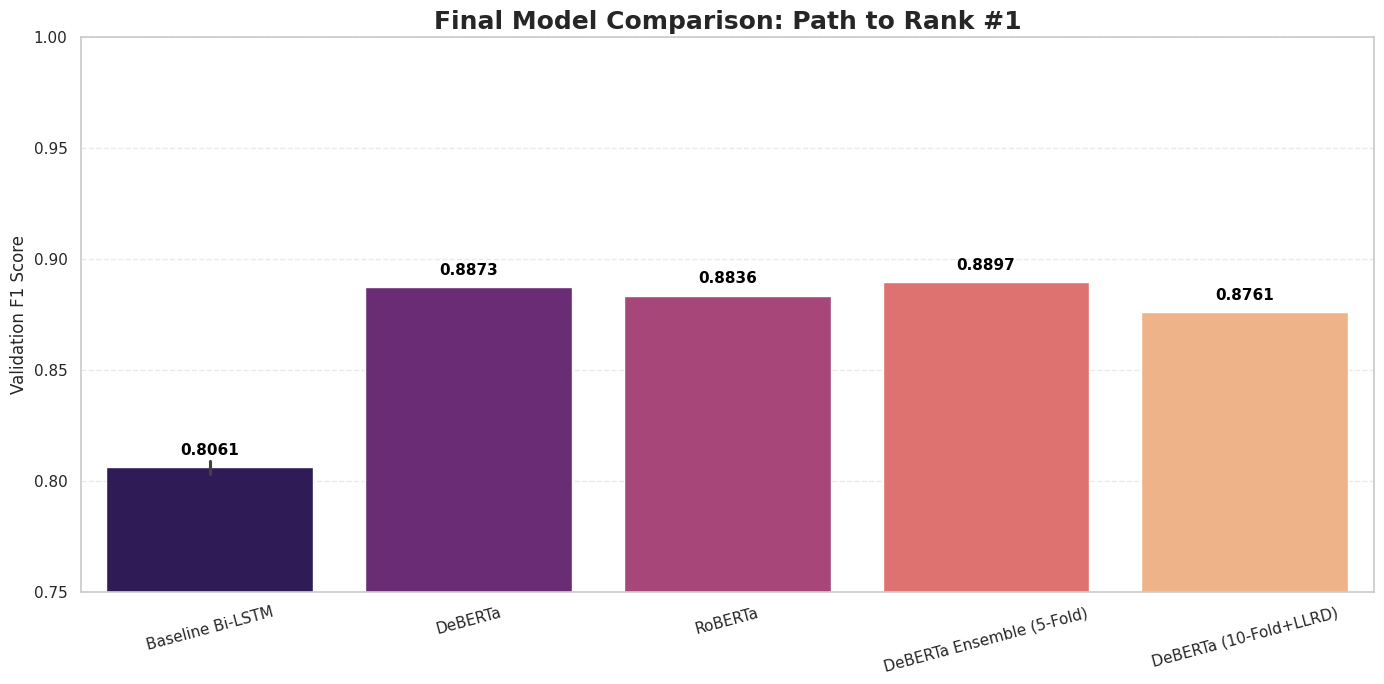


=== Final Leaderboard ===


,Model,Val F1,Val Accuracy
3,DeBERTa Ensemble (5-Fold),0.889667,0.958162
1,DeBERTa,0.887251,0.958656
2,RoBERTa,0.883600,0.955526
5,DeBERTa (10-Fold+LLRD),0.876149,0.952397
4,Baseline Bi-LSTM,0.809047,0.922912
0,Baseline Bi-LSTM,0.803142,0.924559


In [ ]:
def evaluate_grandmaster_on_val(model_paths, tokenizer, val_data):
    dataset = HFDataset.from_list(val_data)
    
    def tokenize_only(examples):
        return tokenizer(examples["tokens"], truncation=True, is_split_into_words=True)
    
    tokenized_ds = dataset.map(tokenize_only, batched=True)
    tokenized_ds.set_format(type='torch', columns=['input_ids', 'attention_mask'])
    data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)
    dataloader = DataLoader(tokenized_ds, batch_size=16, shuffle=False, collate_fn=data_collator)
    
    accumulated_logits = []
    
    for i, path in enumerate(model_paths):
        if i == 0 or (i+1) == len(model_paths):
            print(f"  Validating with model {i+1}/{len(model_paths)}...")
            
        model = AutoModelForTokenClassification.from_pretrained(path).to(device)
        model.eval()
        
        fold_logits = []
        with torch.no_grad():
            for batch in dataloader:
                batch = {k: v.to(device) for k, v in batch.items()}
                outputs = model(**batch)
                fold_logits.append(outputs.logits.cpu())
        
        if i == 0:
            accumulated_logits = fold_logits
        else:
            for b, logits in enumerate(fold_logits):
                accumulated_logits[b] += logits
        
        del model
        torch.cuda.empty_cache()

    final_preds_tags = []
    batch_idx = 0
    
    for batch_logit in accumulated_logits:
        avg_logit = batch_logit / len(model_paths)
        pred_ids = torch.argmax(avg_logit, dim=2).numpy()
        batch_size = pred_ids.shape[0]
        
        for k in range(batch_size):
            item_idx = batch_idx + k
            tokens = val_data[item_idx]["tokens"]
            encoding = tokenizer(tokens, is_split_into_words=True, truncation=True)
            word_ids = encoding.word_ids()
            
            preds = pred_ids[k]
            word_level_pred = []
            prev_word = None
            
            for idx, word_id in enumerate(word_ids):
                if word_id is None: continue
                if word_id != prev_word:
                    word_level_pred.append(id2label[preds[idx]])
                    prev_word = word_id
            
            if len(word_level_pred) < len(tokens):
                word_level_pred += ["O"] * (len(tokens) - len(word_level_pred))
            elif len(word_level_pred) > len(tokens):
                word_level_pred = word_level_pred[:len(tokens)]
            
            word_level_pred = fix_broken_sequences(word_level_pred)
            
            final_preds_tags.append(word_level_pred)
            
        batch_idx += batch_size
        
    return final_preds_tags

gm_preds = evaluate_grandmaster_on_val(opt_model_paths, opt_tokenizer, val_subset)
gm_refs = [[id2label[t] for t in x["ner_tags"]] for x in val_subset]

gm_results = seqeval.compute(predictions=gm_preds, references=gm_refs)
print(f"Final Val F1: {gm_results['overall_f1']:.4f}")

global_results["models"].append("DeBERTa (10-Fold+LLRD)")
global_results["val_f1"].append(gm_results["overall_f1"])
global_results["val_accuracy"].append(gm_results["overall_accuracy"])


plt.figure(figsize=(14, 7))
bars = sns.barplot(x=global_results["models"], y=global_results["val_f1"], palette="magma")

plt.title('Final Model Comparison: Path to Rank #1', fontsize=18, fontweight='bold')
plt.ylim(0.75, 1.0) 
plt.ylabel("Validation F1 Score", fontsize=12)
plt.xticks(rotation=15, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.4)

for p in bars.patches:
    height = p.get_height()
    bars.annotate(f'{height:.4f}', 
                  (p.get_x() + p.get_width() / 2., height), 
                  ha = 'center', va = 'center', 
                  xytext = (0, 12), 
                  textcoords = 'offset points',
                  fontweight='bold', fontsize=11, color='black')

plt.tight_layout()
plt.savefig('./plots/final_comparison_grandmaster.png', dpi=300)
plt.close()

df_final = pd.DataFrame({
    "Model": global_results["models"],
    "Val F1": global_results["val_f1"],
    "Val Accuracy": global_results["val_accuracy"]
})
df_final.sort_values(by="Val F1", ascending=False, inplace=True)
df_final.to_csv("./tables/final_leaderboard.csv", index=False)

print("\n=== Final Leaderboard ===")
display(df_final)